<a href="https://colab.research.google.com/github/carlosgonzalezalanis-arch/M-todos-n-meros-/blob/main/M%C3%A9todo_de_Neville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpolación Iterada: Método de Neville
### Algoritmo 3.1 (Burden & Faires, Sección 3.2) — Prueba con Ejemplo 2

---

## **1. Formulación del Problema y Método**

Dados $n + 1$ nodos distintos $x_0, x_1, \dots, x_n$, sus valores $f(x_0), f(x_1), \dots, f(x_n)$ y un punto de evaluación $x$, el **Método de Neville** calcula de forma recursiva el valor del único polinomio interpolante $P_n(x)$ sin necesidad de construir previamente sus coeficientes.

Sea $Q_{i,j}$ ($0 \le j \le i \le n$) el polinomio interpolante de grado $j$ sobre los nodos $x_{i-j}, x_{i-j+1}, \dots, x_i$ evaluado en $x$:

* **Inicialización (orden $0$):**
  $$Q_{i,0} = f(x_i), \quad i = 0, 1, \dots, n$$

* **Recurrencia iterativa (orden $j \ge 1$):**
  $$Q_{i,j} = \frac{(x - x_{i-j})\,Q_{i,j-1} - (x - x_i)\,Q_{i-1,j-1}}{x_i - x_{i-j}}, \quad i = 1, \dots, n; \quad j = 1, \dots, i$$

La aproximación final buscada corresponde a la esquina inferior derecha de la tabla: $P_n(x) = Q_{n,n}$.

---

## **2. Datos de Prueba: Ejemplo 2 (Burden, Sección 3.2, Tabla 3.6)**

Evaluaremos $P_4(1.5)$ utilizando los $5$ nodos tabulados:

| $i$ | $x_i$ | $f(x_i)$ |
| :---: | :---: | :---: |
| $0$ | $1.0$ | $0.7651977$ |
| $1$ | $1.3$ | $0.6200860$ |
| $2$ | $1.6$ | $0.4554022$ |
| $3$ | $1.9$ | $0.2818186$ |
| $4$ | $2.2$ | $0.1103623$ |


TABLA 3.6: RESULTADOS DEL MÉTODO DE NEVILLE EN x = 1.5
--------------------------------------------------------------------
i   x_i        Q[i,0]      Q[i,1]      Q[i,2]      Q[i,3]      Q[i,4]
--------------------------------------------------------------------
0   1.0      0.7651977
1   1.3      0.6200860   0.5233449
2   1.6      0.4554022   0.5102968   0.5124715
3   1.9      0.2818186   0.5132634   0.5112857   0.5118127
4   2.2      0.1103623   0.5104270   0.5137361   0.5118302   0.5118200

SOLUCIÓN FINAL:  P_4(1.5) = Q[4,4] = 0.5118200



<IPython.core.display.Math object>

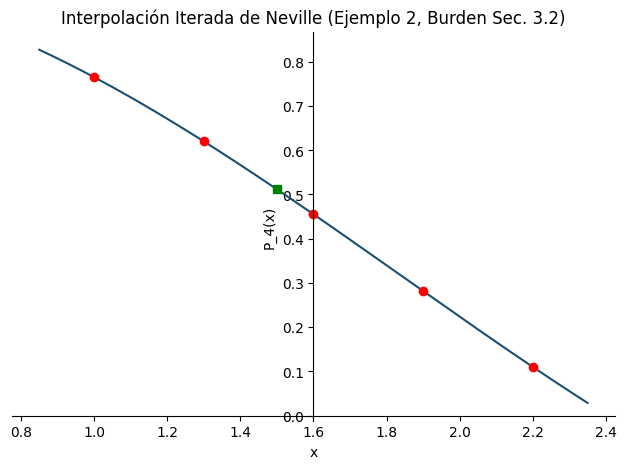

In [1]:
import numpy as np
import sympy as sp
from sympy.plotting import plot
from IPython.display import display, Math


def metodo_neville(x_nodos, fx_nodos, x_eval):
    """Evalúa P_n(x_eval) mediante el Algoritmo 3.1 de Neville (Burden, Sec. 3.2)."""
    n = len(x_nodos) - 1
    # 'np.zeros((filas, cols))' crea la matriz triangular para almacenar Q_{i,j}
    Q = np.zeros((n + 1, n + 1), dtype=float)

    # Slicing '[:, 0]': carga los valores iniciales Q_{i,0} = f(x_i)
    Q[:, 0] = fx_nodos

    # 'range(1, n + 1)' itera de 1 hasta n (el extremo derecho es exclusivo)
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            numerador = (x_eval - x_nodos[i - j]) * Q[i, j - 1] - (x_eval - x_nodos[i]) * Q[i - 1, j - 1]
            denominador = x_nodos[i] - x_nodos[i - j]
            Q[i, j] = numerador / denominador

    # Retorna el valor final Q[n, n] = P_n(x_eval) y la tabla completa Q
    return Q[n, n], Q


def construir_y_graficar_neville(x_nodos, fx_nodos, x_eval, valor_eval):
    """Construye el polinomio simbólico por recurrencia de Neville y lo grafica con SymPy."""
    # 'sp.Symbol' define 'x' como variable simbólica algebraica
    x = sp.Symbol('x')
    n = len(x_nodos) - 1

    # List comprehension bidimensional para almacenar expresiones simbólicas
    Q_sym = [[sp.Integer(0)] * (n + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        Q_sym[i][0] = sp.Float(fx_nodos[i], 7)

    for i in range(1, n + 1):
        for j in range(1, i + 1):
            num = (x - sp.Float(x_nodos[i - j])) * Q_sym[i][j - 1] - (x - sp.Float(x_nodos[i])) * Q_sym[i - 1][j - 1]
            # 'sp.expand()' simplifica y agrupa términos semejantes del polinomio
            Q_sym[i][j] = sp.expand(num / sp.Float(x_nodos[i] - x_nodos[i - j]))

    P_x = Q_sym[n][n]
    display(Math(r"\color{#1B4F72}{\textbf{Polinomio de Neville: }} P_4(x) = " + sp.latex(P_x)))

    # Grafica la curva P_4(x), los nodos originales ('ro') y el punto evaluado ('gs')
    plot(
        P_x,
        (x, min(x_nodos) - 0.15, max(x_nodos) + 0.15),
        title="Interpolación Iterada de Neville (Ejemplo 2, Burden Sec. 3.2)",
        xlabel="x",
        ylabel="P_4(x)",
        line_color="#1B4F72",
        markers=[
            {"args": [list(x_nodos), list(fx_nodos), "ro"]},
            {"args": [[x_eval], [valor_eval], "gs"]}
        ]
    )
    return P_x


# ==============================================================================
# EJECUCIÓN CON LOS DATOS DEL EJEMPLO 2 (Burden, Sec. 3.2, Tabla 3.6)
# ==============================================================================
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
fx_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x_objetivo = 1.5

# Desempaquetado de la tupla devuelta por el algoritmo
resultado, tabla_Q = metodo_neville(x_datos, fx_datos, x_objetivo)

print("TABLA 3.6: RESULTADOS DEL MÉTODO DE NEVILLE EN x = 1.5")
print("-" * 68)
print(f"{'i':<3} {'x_i':<6} {'Q[i,0]':>10} {'Q[i,1]':>11} {'Q[i,2]':>11} {'Q[i,3]':>11} {'Q[i,4]':>11}")
print("-" * 68)

for i in range(len(x_datos)):
    # Formateo tabular a 7 decimales mediante f-strings
    fila = " ".join(f"{tabla_Q[i, j]:>11.7f}" for j in range(i + 1))
    print(f"{i:<3} {x_datos[i]:<6.1f} {fila}")

print("\n" + "=" * 68)
print(f"SOLUCIÓN FINAL:  P_4({x_objetivo}) = Q[4,4] = {resultado:.7f}")
print("=" * 68 + "\n")

# Construcción simbólica y gráfica con SymPy
P_neville = construir_y_graficar_neville(x_datos, fx_datos, x_objetivo, resultado)


## **3. Solución Final**
Aproximación obtenida mediante el Método de Neville (Tabla 3.6):

P_4(1.5) = Q_{4,4} = $\mathbf{0.5118200}$
 **Polinomio interpolante resultante:**

 $P_4(x) = 0.0018251x^4 + 0.0552928x^3 - 0.3430466x^2 + 0.0733913x + 0.9777351$

